# **Time Series**

# **1. Import Library**

In [1]:
import numpy as np
import pandas as pd
from keras.layers import Dense, LSTM
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# **2. Collecting Dataset**
Dataset yang digunakan adalah dari :
https://www.kaggle.com/sumanthvrao/daily-climate-time-series-data

In [ ]:
data_train = pd.read_csv('DailyDelhiClimateTrain.csv')
print(data_train.info())
print(f"\nThere data is null\n{data_train.isnull().sum()}")
print(data_train)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1462 non-null   object 
 1   meantemp      1462 non-null   float64
 2   humidity      1462 non-null   float64
 3   wind_speed    1462 non-null   float64
 4   meanpressure  1462 non-null   float64
dtypes: float64(4), object(1)
memory usage: 57.2+ KB
None

There data is null
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64
            date   meantemp    humidity  wind_speed  meanpressure
0     2013-01-01  10.000000   84.500000    0.000000   1015.666667
1     2013-01-02   7.400000   92.000000    2.980000   1017.800000
2     2013-01-03   7.166667   87.000000    4.633333   1018.666667
3     2013-01-04   8.666667   71.333333    1.233333   1017.166667
4     2013-01-05   6.000000   86.833333    3.700000   1016.500000
...          ...

# **3. Cleaning Dataset**
Menghapus dataset kosong dan yang tidak diperlukan

# **4. Data Visualization**

<Axes: >

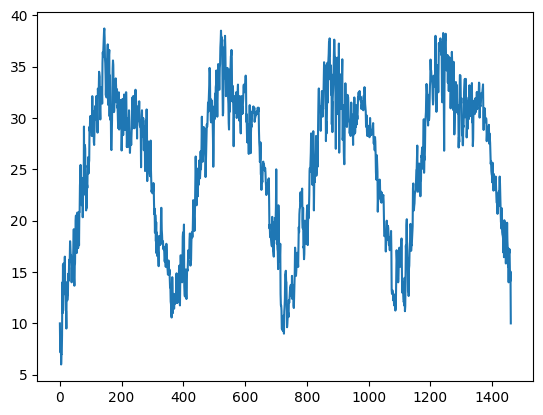

In [ ]:
# data_train[:32]
data_train['meantemp'].plot()

Text(0, 0.5, 'Temp')

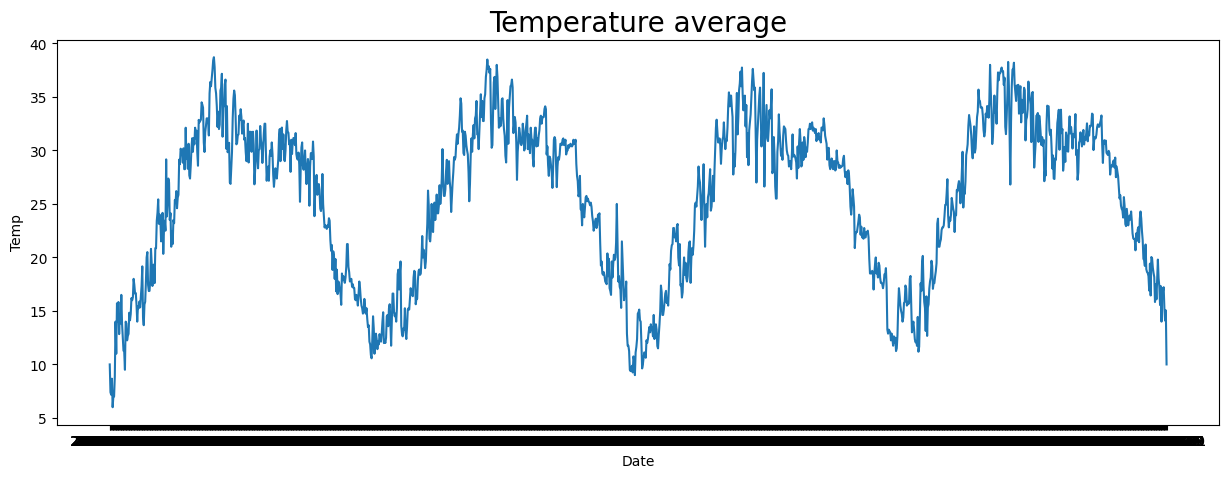

In [ ]:
dates = data_train['date'].values
tempTrain  = data_train['meantemp'].values

plt.figure(figsize=(15,5))
plt.plot(dates, tempTrain)
plt.title('Temperature average',
          fontsize=20);
plt.xlabel("Date")
plt.ylabel("Temp")

# **5. Pre-Processing Dataset**

## **Normalization**

In [ ]:
print(tempTrain)

# membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
dataTrain = tf.expand_dims(tempTrain, axis=-1)
print("membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]")
print(dataTrain)
print("-----------------------------------------------------------\n")

# Normalization
scaler = MinMaxScaler()
scaledDataTrain = scaler.fit_transform(dataTrain)
print("Scaled")
print(scaledDataTrain)
print("-----------------------------------------------------------\n")

[10.          7.4         7.16666667 ... 14.0952381  15.05263158
 10.        ]
membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
tf.Tensor(
[[10.        ]
 [ 7.4       ]
 [ 7.16666667]
 ...
 [14.0952381 ]
 [15.05263158]
 [10.        ]], shape=(1462, 1), dtype=float64)
-----------------------------------------------------------

Scaled
[[0.12227074]
 [0.04279476]
 [0.0356623 ]
 ...
 [0.24745269]
 [0.276718  ]
 [0.12227074]]
-----------------------------------------------------------



## **Split**

In [ ]:
trainData, testData = train_test_split(scaledDataTrain, test_size = 0.2, shuffle=False)

# **Checking Threshold**

In [ ]:
threshold_mae_train = (trainData.max() - trainData.min()) * 10/100
threshold_mae_test = (testData.max() - testData.min()) * 10/100
print(f"Train Threshold : {threshold_mae_train} Test Threshold : {threshold_mae_test}")

Train Threshold : 0.1 Test Threshold : 0.08642318380309645


## **Batching Dataset**

In [ ]:
def windowed_dataset(series, window_size, batch_size, shuffle_buffer):

    # membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
    # dataTrain = tf.expand_dims(tempTrain, axis=-1)
    # print("membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]")
    # print(dataTrain)
    # print("-----------------------------------------------------------\n")

    # membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]
    ds = tf.data.Dataset.from_tensor_slices(series)
    print("membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]")
    print(list(ds.as_numpy_iterator()))
    print("-----------------------------------------------------------\n")

    # membuat window dengan jumlah isi yang telah ditentukan
    ds = ds.window(window_size + 1, shift=1, drop_remainder=True)
    print("membuat window dengan jumlah isi yang telah ditentukan")
    i = 0
    for window in ds:
      print(list(window.as_numpy_iterator()))
      i+=1
      if i == 2:
        break
    print("-----------------------------------------------------------\n")

    # membuat array menjadi [[num1] [...] [numN]]
    ds = ds.flat_map(lambda w: w.batch(window_size + 1))
    print("membuat array menjadi [[num1] [...] [numN]]")
    i = 0
    for window in ds:
      print(window)
      i+=1
      if i == 2:
        break
    print("-----------------------------------------------------------\n")

    # dibuat acak
    ds = ds.shuffle(shuffle_buffer)
    print("dibuat acak")
    i = 0
    for window in ds:
      print(window)
      i+=1
      if i == 2:
        break
    print("-----------------------------------------------------------\n")

    # mapping
    ds = ds.map(lambda w: (w[:-1], w[-1:]))
    print("mapping")
    i = 0
    for window in ds:
      print(window)
      i+=1
      if i == 2:
        break
    print("-----------------------------------------------------------\n")

    return ds.batch(batch_size).prefetch(1)

windowedTrainData = windowed_dataset(trainData, window_size=60, batch_size=100, shuffle_buffer=1000)
windowedTestData = windowed_dataset(testData, window_size=60, batch_size=100, shuffle_buffer=1000)

# hasil windowed batch dataset
i = 0
print("hasil windowed batch dataset")
for window in train_set:
  print(window)
  i+=1
  if i == 2:
    break
print("-----------------------------------------------------------\n")

membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]
[array([0.12227074]), array([0.04279476]), array([0.0356623]), array([0.08151383]), array([0.]), array([0.03056769]), array([0.03056769]), array([0.08733624]), array([0.24454148]), array([0.15283843]), array([0.29694323]), array([0.24454148]), array([0.30058224]), array([0.20887918]), array([0.26637555]), array([0.23944687]), array([0.3209607]), array([0.23944687]), array([0.19868996]), array([0.16157205]), array([0.15895197]), array([0.1069869]), array([0.24454148]), array([0.23944687]), array([0.19104803]), array([0.20378457]), array([0.20960699]), array([0.27001456]), array([0.24836245]), array([0.26637555]), array([0.31179039]), array([0.30567686]), array([0.31441048]), array([0.36681223]), array([0.34934498]), array([0.32478166]), array([0.32605531]), array([0.29344978]), array([0.24454148]), array([0.28820961]), array([0.28275109]), array([0.3018559]), array([0.2852984]), array([0.31441048]), array([0.3464337

## **Modelling**

In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.LSTM(60, return_sequences=True),
  tf.keras.layers.LSTM(60),
  tf.keras.layers.Dense(30, activation="relu"),
  tf.keras.layers.Dense(10, activation="relu"),
  tf.keras.layers.Dense(1),
])

optimizer = tf.keras.optimizers.SGD(learning_rate=10.0000e-04, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mae"])

# **6. Fitting Dataset**

In [ ]:
history = model.fit(windowedTrainData,epochs=100,verbose=2,validation_data=windowedTestData)

Epoch 1/100
12/12 - 7s - loss: 0.1816 - mae: 0.5610 - val_loss: 0.2011 - val_mae: 0.6083 - 7s/epoch - 599ms/step
Epoch 2/100
12/12 - 1s - loss: 0.1233 - mae: 0.4471 - val_loss: 0.1208 - val_mae: 0.4599 - 1s/epoch - 109ms/step
Epoch 3/100
12/12 - 1s - loss: 0.0624 - mae: 0.3016 - val_loss: 0.0553 - val_mae: 0.2969 - 1s/epoch - 108ms/step
Epoch 4/100
12/12 - 1s - loss: 0.0283 - mae: 0.2040 - val_loss: 0.0263 - val_mae: 0.2025 - 1s/epoch - 109ms/step
Epoch 5/100
12/12 - 1s - loss: 0.0181 - mae: 0.1662 - val_loss: 0.0166 - val_mae: 0.1617 - 1s/epoch - 108ms/step
Epoch 6/100
12/12 - 1s - loss: 0.0165 - mae: 0.1550 - val_loss: 0.0140 - val_mae: 0.1470 - 1s/epoch - 111ms/step
Epoch 7/100
12/12 - 1s - loss: 0.0163 - mae: 0.1520 - val_loss: 0.0137 - val_mae: 0.1452 - 1s/epoch - 109ms/step
Epoch 8/100
12/12 - 2s - loss: 0.0160 - mae: 0.1511 - val_loss: 0.0139 - val_mae: 0.1470 - 2s/epoch - 180ms/step
Epoch 9/100
12/12 - 2s - loss: 0.0158 - mae: 0.1507 - val_loss: 0.0142 - val_mae: 0.1490 - 2s/ep

# **7. Visualization**

## **Accuracy**

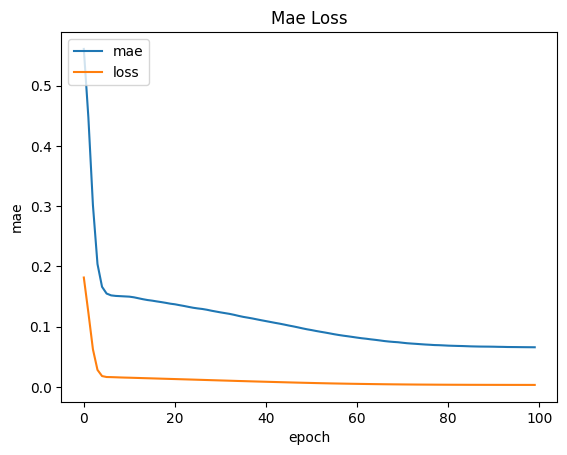

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['mae'])
plt.plot(history.history['loss'])
plt.title('Mae Loss')
plt.ylabel('mae')
plt.xlabel('epoch')
plt.legend(['mae', 'loss'], loc='upper left')
plt.show()

## **Loss**

In [ ]:
# plt.plot(history.history['loss'])
# plt.plot(history.history['val_loss'])
# plt.title('Loss Model')
# plt.ylabel('loss')
# plt.xlabel('epoch')
# plt.legend(['train', 'test'], loc='upper left')
# plt.show()